# 04a - Logistic Regression Screening Model

Here we train and tune Logistic Regression models on `results/train.csv` using the shared 5-fold CV splits. `results/test.csv` is not touched.

In [1]:
# import shared helpers and libraries
import json
import sys
from pathlib import Path

sys.path.append("..")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.calibration import CalibratedClassifierCV, CalibrationDisplay
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import ConfusionMatrixDisplay, brier_score_loss, confusion_matrix
from sklearn.pipeline import Pipeline

from src import evaluate, preprocess
from src.feature_sets import FEATURE_SETS, raw_input_cols

sns.set_theme(style="whitegrid")

df, all_raw_cols = preprocess.load_train_data()
y = df["target"].to_numpy()
splits = evaluate.make_cv_splits(df)
print(f"train shape: {df.shape} | positive rate: {y.mean():.4f} | folds: {len(splits)}")

train shape: (12378, 66) | positive rate: 0.2961 | folds: 5


## 1. Compare the 6 Shared Feature Sets

We test all 6 feature sets from `src/feature_sets.py` with default `LogisticRegression` on the same 5 folds.

In [2]:
# helper to run leak-free 5-fold CV for logistic regression
def run_logreg_cv(cols, C=1.0, class_weight=None):
    raw_cols = raw_input_cols(cols)
    oof = np.zeros(len(df))

    for tr, va in splits:
        X_tr = df.iloc[tr][raw_cols]
        X_va = df.iloc[va][raw_cols]
        pipe = Pipeline([
            ("prep", preprocess.build_preprocessor("logreg", cols, use_engineered=True)),
            ("clf", LogisticRegression(C=C, class_weight=class_weight, max_iter=1000, random_state=evaluate.SEED)),
        ])
        pipe.fit(X_tr, y[tr])
        oof[va] = pipe.predict_proba(X_va)[:, 1]

    _, metrics = evaluate.find_best_threshold(y, oof)
    metrics["brier"] = round(float(brier_score_loss(y, oof)), 4)
    return oof, metrics

# run all 6 shared feature sets with default hyperparameters
fs_rows = []
fs_oof = {}
for set_name, cols in FEATURE_SETS.items():
    oof, m = run_logreg_cv(cols)
    fs_oof[set_name] = oof
    fs_rows.append({
        "feature_set": set_name,
        "n_features": len(cols),
        **m,
    })

fs_df = pd.DataFrame(fs_rows)
show_cols = ["feature_set", "n_features", "roc_auc", "pr_auc", "f2", "recall", "specificity", "precision", "threshold"]
display(fs_df[show_cols])

,feature_set,n_features,roc_auc,pr_auc,f2,recall,specificity,precision,threshold
0,ada_like_7,7,0.7408,0.5014,0.6059,0.6497,0.7007,0.4772,0.319
1,custom_10,10,0.7571,0.5306,0.6354,0.6854,0.7023,0.4920,0.306
2,no_device_15,15,0.7621,0.5417,0.6429,0.6952,0.7006,0.4941,0.312
3,practical_20,20,0.7624,0.5449,0.6434,0.6958,0.7007,0.4944,0.313
4,top_30,30,0.7612,0.5428,0.6383,0.6895,0.7007,0.4921,0.315
5,all_64,64,0.7611,0.5397,0.6418,0.6939,0.7007,0.4937,0.313


`practical_20` reaches the top scores (0.7624 ROC-AUC, 0.5449 PR-AUC, 0.6434 F2), and `no_device_15` is almost identical (0.7621 ROC-AUC, 0.6429 F2) without blood pressure or waist measurements. Adding more variables in `top_30` and `all_64` slightly lowers CV scores because extra noisy survey columns do not help a linear model.

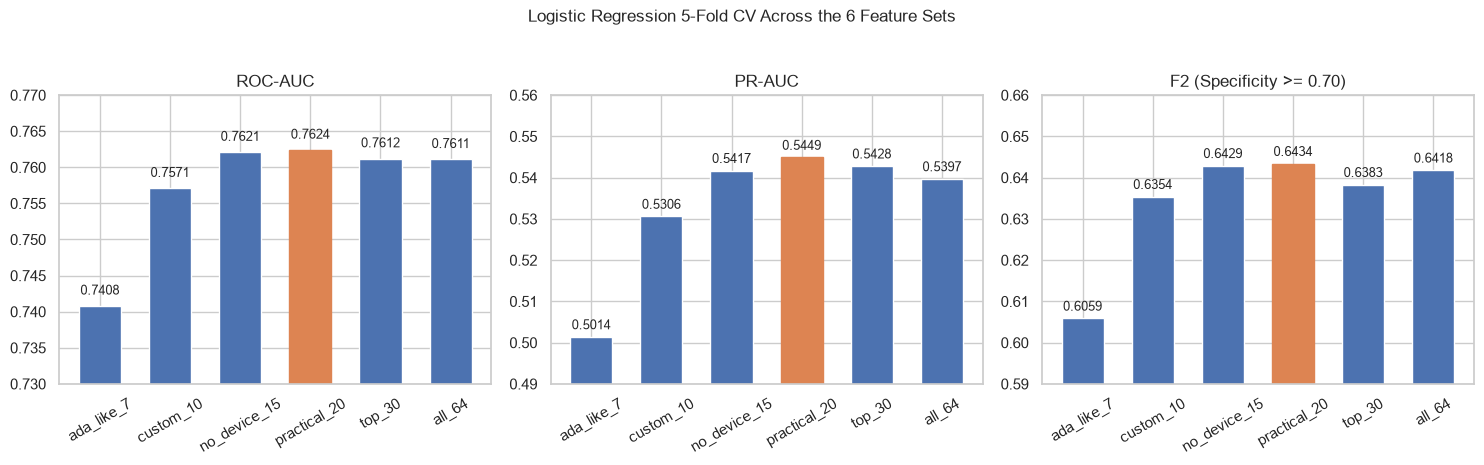

In [3]:
# plot ROC-AUC, PR-AUC, and F2 across the 6 feature sets
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
plot_specs = [
    ("roc_auc", "ROC-AUC", (0.73, 0.77)),
    ("pr_auc", "PR-AUC", (0.49, 0.56)),
    ("f2", "F2 (Specificity >= 0.70)", (0.59, 0.66)),
]

for ax, (col, title, ylim) in zip(axes, plot_specs):
    bars = ax.bar(fs_df["feature_set"], fs_df[col], color="#4C72B0", width=0.6)
    best_idx = int(fs_df[col].idxmax())
    bars[best_idx].set_color("#DD8452")
    ax.set_title(title)
    ax.set_ylim(*ylim)
    ax.tick_params(axis="x", rotation=30)
    for bar, val in zip(bars, fs_df[col]):
        ax.text(bar.get_x() + bar.get_width() / 2, val + 0.0012, f"{val:.4f}", ha="center", va="bottom", fontsize=9)

plt.suptitle("Logistic Regression 5-Fold CV Across the 6 Feature Sets", y=1.03, fontsize=12)
plt.tight_layout()
plt.show()

Screening performance rises quickly from `ada_like_7` to `no_device_15` and peaks at `practical_20` on all three metrics. We carry `practical_20` and `no_device_15` forward as the best two feature sets for hyperparameter tuning.

## 2. Hyperparameter Tuning on the Top 2 Feature Sets

We tune `C` (`0.01, 0.05, 0.2, 1.0, 5.0`) and `class_weight` (`None` vs `"balanced"`) on `practical_20` and `no_device_15` across the same 5 folds.

In [4]:
# test C and class_weight combinations on the top 2 feature sets
TOP_2_SETS = ["practical_20", "no_device_15"]
C_VALUES = [0.01, 0.05, 0.2, 1.0, 5.0]
CLASS_WEIGHTS = [None, "balanced"]

# fit the leak-free preprocessor once per fold for each feature set
fold_matrices = {}
for set_name in TOP_2_SETS:
    cols = FEATURE_SETS[set_name]
    raw_cols = raw_input_cols(cols)
    fold_list = []
    for tr, va in splits:
        prep = preprocess.build_preprocessor("logreg", cols, use_engineered=True)
        Xt_tr = prep.fit_transform(df.iloc[tr][raw_cols])
        Xt_va = prep.transform(df.iloc[va][raw_cols])
        fold_list.append((tr, va, Xt_tr, Xt_va))
    fold_matrices[set_name] = fold_list

tuning_rows = []
tuning_oof = {}
for set_name in TOP_2_SETS:
    for cw in CLASS_WEIGHTS:
        cw_label = "none" if cw is None else cw
        for C_val in C_VALUES:
            oof = np.zeros(len(df))
            for tr, va, Xt_tr, Xt_va in fold_matrices[set_name]:
                clf = LogisticRegression(
                    C=C_val, class_weight=cw, max_iter=1000, random_state=evaluate.SEED
                )
                clf.fit(Xt_tr, y[tr])
                oof[va] = clf.predict_proba(Xt_va)[:, 1]

            _, m = evaluate.find_best_threshold(y, oof)
            m["brier"] = round(float(brier_score_loss(y, oof)), 4)
            tuning_oof[(set_name, C_val, cw)] = oof
            tuning_rows.append({
                "feature_set": set_name,
                "C": C_val,
                "class_weight": cw_label,
                **m,
            })

tune_df = pd.DataFrame(tuning_rows)
tune_cols = ["feature_set", "C", "class_weight", "roc_auc", "pr_auc", "f2", "recall", "specificity", "threshold", "brier"]
display(tune_df[tune_cols])

,feature_set,C,class_weight,roc_auc,pr_auc,f2,recall,specificity,threshold,brier
0,practical_20,0.01,none,0.7616,0.5432,0.6435,0.6952,0.7027,0.317,0.1727
1,practical_20,0.05,none,0.7626,0.5449,0.6421,0.6939,0.7017,0.314,0.1723
2,practical_20,0.20,none,0.7626,0.5448,0.6439,0.6966,0.7003,0.313,0.1723
3,practical_20,1.00,none,0.7624,0.5449,0.6434,0.6958,0.7007,0.313,0.1723
4,practical_20,5.00,none,0.7623,0.5451,0.6432,0.6958,0.7001,0.313,0.1724
5,practical_20,0.01,balanced,0.7617,0.5428,0.6441,0.6969,0.7002,0.520,0.2002
6,practical_20,0.05,balanced,0.7626,0.5441,0.6423,0.6947,0.7001,0.518,0.1997
7,practical_20,0.20,balanced,0.7625,0.5436,0.6403,0.6920,0.7009,0.519,0.1997
8,practical_20,1.00,balanced,0.7624,0.5437,0.6399,0.6917,0.7002,0.519,0.1997
9,practical_20,5.00,balanced,0.7623,0.5436,0.6385,0.6898,0.7008,0.520,0.1997


`practical_20` with `C=0.2` and `class_weight=None` gives the best overall balance: tied top ROC-AUC (0.7626), strong PR-AUC (0.5448), top calibrated F2 (0.6439), and tied lowest Brier score (0.1723). Using `class_weight="balanced"` shifts thresholds from ~0.31 to ~0.52, lowers PR-AUC, and worsens Brier error from 0.1723 to 0.1997.

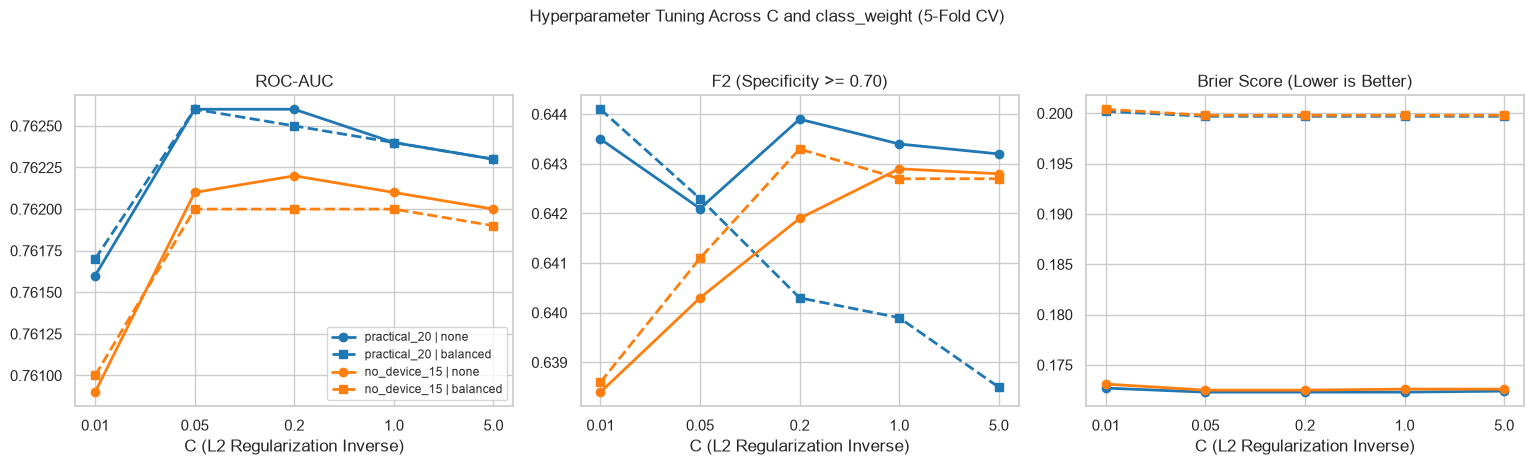

[Selected Best LogReg (practical_20, C=0.2, class_weight=None)]
  ROC-AUC: 0.7626 | PR-AUC: 0.5448 | F2: 0.6439 | Thr: 0.3130
  Recall: 0.6966 | Specificity: 0.7003 | Precision: 0.4944 | TP=2553 FP=2611 TN=6102 FN=1112
  Brier: 0.1723


In [5]:
# plot tuning curves across C for ROC-AUC, F2, and Brier score
fig, axes = plt.subplots(1, 3, figsize=(15.5, 4.5))
x_labels = [str(c) for c in C_VALUES]
styles = [
    ("practical_20", "none", "#1f77b4", "-", "o", "practical_20 | none"),
    ("practical_20", "balanced", "#1f77b4", "--", "s", "practical_20 | balanced"),
    ("no_device_15", "none", "#ff7f0e", "-", "o", "no_device_15 | none"),
    ("no_device_15", "balanced", "#ff7f0e", "--", "s", "no_device_15 | balanced"),
]

for ax, (metric, title) in zip(axes, [("roc_auc", "ROC-AUC"), ("f2", "F2 (Specificity >= 0.70)"), ("brier", "Brier Score (Lower is Better)")]):
    for s_name, cw_lbl, color, ls, marker, label in styles:
        sub = tune_df[(tune_df["feature_set"] == s_name) & (tune_df["class_weight"] == cw_lbl)]
        ax.plot(x_labels, sub[metric], color=color, linestyle=ls, marker=marker, linewidth=2, label=label)
    ax.set_title(title)
    ax.set_xlabel("C (L2 Regularization Inverse)")

axes[0].legend(fontsize=8.5, loc="lower right")
plt.suptitle("Hyperparameter Tuning Across C and class_weight (5-Fold CV)", y=1.03, fontsize=12)
plt.tight_layout()
plt.show()

best_feature_set = "practical_20"
best_C = 0.2
best_class_weight = None
best_oof = tuning_oof[(best_feature_set, best_C, best_class_weight)]
best_thr, best_metrics = evaluate.find_best_threshold(y, best_oof)
best_metrics["brier"] = round(float(brier_score_loss(y, best_oof)), 4)
evaluate.print_metrics("Selected Best LogReg (practical_20, C=0.2, class_weight=None)", best_metrics)
print(f"  Brier: {best_metrics['brier']:.4f}")

Moderate L2 regularization (`C=0.2`) improves over both strong shrinkage (`C=0.01`, which underfits) and weak shrinkage (`C=5.0`). We lock `practical_20` with `C=0.2` and `class_weight=None` as our final Logistic Regression configuration.

## 3. Calibration and Threshold Analysis

We check probability calibration on out-of-fold predictions, compare against inner-fold Platt (`sigmoid`) scaling, inspect the confusion matrix at `specificity >= 0.70`, and build the fixed referral rate table (`20% / 30% / 40%`).

In [6]:
# run leak-free inner-fold Platt (sigmoid) calibration check on the selected model
best_cols = FEATURE_SETS[best_feature_set]
best_raw_cols = raw_input_cols(best_cols)
platt_oof = np.zeros(len(df))

for tr, va in splits:
    base_pipe = Pipeline([
        ("prep", preprocess.build_preprocessor("logreg", best_cols, use_engineered=True)),
        ("clf", LogisticRegression(C=best_C, class_weight=best_class_weight, max_iter=1000, random_state=evaluate.SEED)),
    ])
    cal_model = CalibratedClassifierCV(base_pipe, method="sigmoid", cv=3)
    cal_model.fit(df.iloc[tr][best_raw_cols], y[tr])
    platt_oof[va] = cal_model.predict_proba(df.iloc[va][best_raw_cols])[:, 1]

_, platt_metrics = evaluate.find_best_threshold(y, platt_oof)
platt_metrics["brier"] = round(float(brier_score_loss(y, platt_oof)), 4)

cal_df = pd.DataFrame([
    {"probability_source": "Raw LogReg OOF", **best_metrics},
    {"probability_source": "Platt (sigmoid, inner 3-fold)", **platt_metrics},
])
cal_cols = ["probability_source", "brier", "roc_auc", "pr_auc", "f2", "recall", "specificity", "precision", "threshold"]
display(cal_df[cal_cols])

,probability_source,brier,roc_auc,pr_auc,f2,recall,specificity,precision,threshold
0,Raw LogReg OOF,0.1723,0.7626,0.5448,0.6439,0.6966,0.7003,0.4944,0.313
1,"Platt (sigmoid, inner 3-fold)",0.1723,0.7626,0.5449,0.6428,0.6952,0.7004,0.4940,0.314


Raw Logistic Regression probabilities are already well calibrated (`Brier = 0.1723`), and inner-fold Platt scaling gives the exact same Brier score while slightly lowering F2 (`0.6439` to `0.6428`). We keep the raw Logistic Regression probabilities without an extra calibration wrapper.

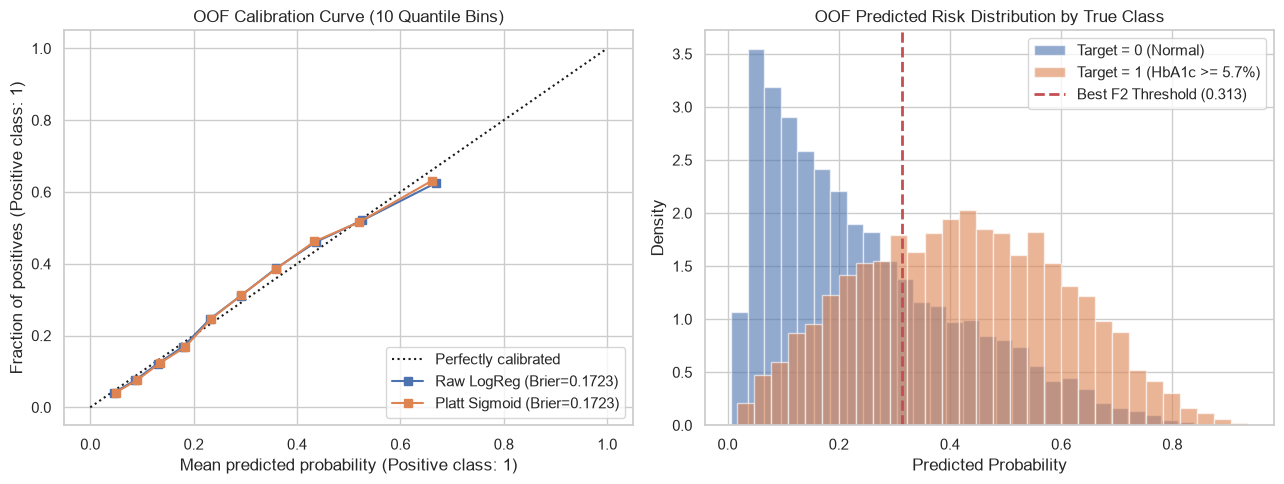

In [7]:
# plot calibration curve and OOF probability distribution
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

CalibrationDisplay.from_predictions(
    y, best_oof, n_bins=10, strategy="quantile", name=f"Raw LogReg (Brier={best_metrics['brier']:.4f})", ax=axes[0]
)
CalibrationDisplay.from_predictions(
    y, platt_oof, n_bins=10, strategy="quantile", name=f"Platt Sigmoid (Brier={platt_metrics['brier']:.4f})", ax=axes[0]
)
axes[0].set_title("OOF Calibration Curve (10 Quantile Bins)")

axes[1].hist(best_oof[y == 0], bins=30, alpha=0.6, label="Target = 0 (Normal)", color="#4C72B0", density=True)
axes[1].hist(best_oof[y == 1], bins=30, alpha=0.6, label="Target = 1 (HbA1c >= 5.7%)", color="#DD8452", density=True)
axes[1].axvline(best_thr, color="#C44E52", linestyle="--", linewidth=2, label=f"Best F2 Threshold ({best_thr:.3f})")
axes[1].set_title("OOF Predicted Risk Distribution by True Class")
axes[1].set_xlabel("Predicted Probability")
axes[1].set_ylabel("Density")
axes[1].legend()

plt.tight_layout()
plt.show()

Both calibration curves sit right on the ideal diagonal across all 10 risk deciles. The `0.313` threshold separates higher-risk adults cleanly while keeping false alarms under 30% of healthy participants.

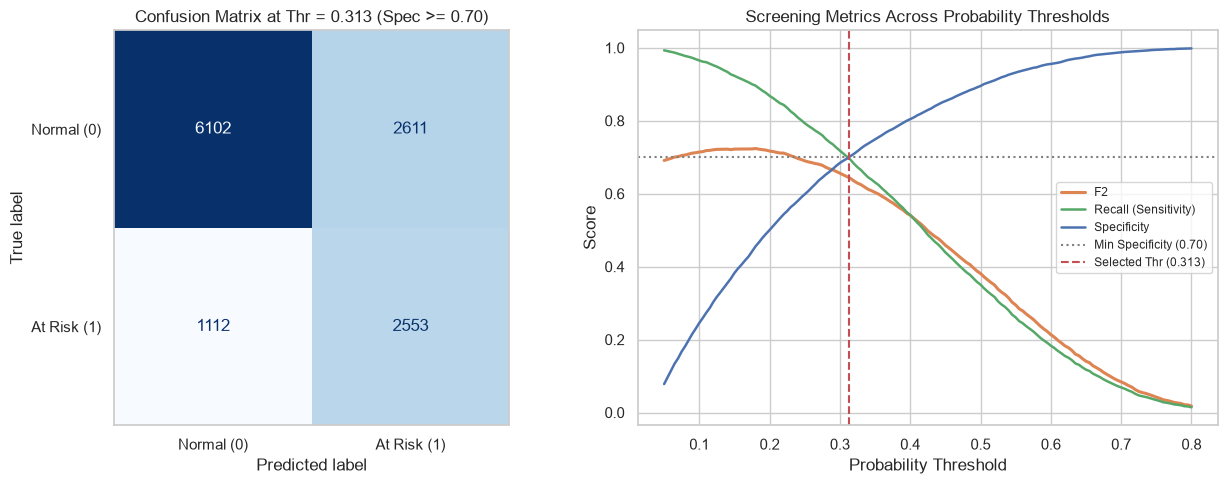

In [8]:
# plot confusion matrix at best F2 threshold (specificity >= 0.70) and threshold trade-off curves
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

y_pred_best = (best_oof >= best_thr).astype(int)
cm = confusion_matrix(y, y_pred_best, labels=[0, 1])
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["Normal (0)", "At Risk (1)"])
disp.plot(ax=axes[0], cmap="Blues", values_format="d", colorbar=False)
axes[0].grid(False)
axes[0].set_title(f"Confusion Matrix at Thr = {best_thr:.3f} (Spec >= 0.70)")

thr_grid = np.linspace(0.05, 0.80, 151)
rec_list, spec_list, f2_list = [], [], []
for t in thr_grid:
    m_t = evaluate.compute_metrics(y, best_oof, t)
    rec_list.append(m_t["recall"])
    spec_list.append(m_t["specificity"])
    f2_list.append(m_t["f2"])

axes[1].plot(thr_grid, f2_list, label="F2", linewidth=2.2, color="#DD8452")
axes[1].plot(thr_grid, rec_list, label="Recall (Sensitivity)", linewidth=1.8, color="#55A868")
axes[1].plot(thr_grid, spec_list, label="Specificity", linewidth=1.8, color="#4C72B0")
axes[1].axhline(0.70, color="gray", linestyle=":", label="Min Specificity (0.70)")
axes[1].axvline(best_thr, color="#C44E52", linestyle="--", label=f"Selected Thr ({best_thr:.3f})")
axes[1].set_title("Screening Metrics Across Probability Thresholds")
axes[1].set_xlabel("Probability Threshold")
axes[1].set_ylabel("Score")
axes[1].legend(fontsize=8.5)

plt.tight_layout()
plt.show()

At `threshold = 0.313`, the model catches 2,553 of 3,665 undiagnosed cases (`69.66%` recall) and spares 6,102 of 8,713 healthy adults (`70.03%` specificity) from blood testing. Nearly half of all referred adults (`49.44%` precision) truly have elevated HbA1c, compared with `29.61%` in unscreened testing.

In [9]:
# build fixed referral rate table for top 20%, 30%, and 40% risk budgets
referral_rows = []
for rate in [0.20, 0.30, 0.40]:
    thr_r = float(np.quantile(best_oof, 1.0 - rate))
    m_r = evaluate.compute_metrics(y, best_oof, thr_r)
    referred_n = int(m_r["tp"] + m_r["fp"])
    referral_rows.append({
        "referral_rate": round(rate, 2),
        "actual_referral_rate": round(referred_n / len(y), 4),
        "referred_count": referred_n,
        "threshold": m_r["threshold"],
        "recall": m_r["recall"],
        "specificity": m_r["specificity"],
        "precision": m_r["precision"],
        "f2": m_r["f2"],
        "tp": m_r["tp"],
        "fp": m_r["fp"],
        "tn": m_r["tn"],
        "fn": m_r["fn"],
    })

referral_df = pd.DataFrame(referral_rows)
display(referral_df)

,referral_rate,actual_referral_rate,referred_count,threshold,recall,specificity,precision,f2,tp,fp,tn,fn
0,0.2,0.2,2476,0.4784,0.3874,0.8788,0.5735,0.4143,1420,1056,7657,2245
1,0.3,0.3,3714,0.3982,0.5432,0.8022,0.5361,0.5418,1991,1723,6990,1674
2,0.4,0.4,4951,0.3241,0.6742,0.7154,0.4991,0.6300,2471,2480,6233,1194


If clinic budget only allows blood tests for the top `20%` highest-risk adults, precision reaches `57.35%` while capturing `38.74%` of all cases. Expanding referral to `40%` (`threshold = 0.3241`) captures `67.42%` of cases with `71.54%` specificity, very close to our main `0.3130` screening rule.

## 4. Save Out-of-Fold Predictions and CV Summary

We save `experiments/logreg_oof.csv` in the exact row order of `results/train.csv` and write all CV metrics to `experiments/logreg_cv.json`.

In [10]:
# save OOF predictions and CV summary JSON in experiments/
exp_dir = Path("..") / "experiments"
exp_dir.mkdir(parents=True, exist_ok=True)

oof_path = exp_dir / "logreg_oof.csv"
oof_df = pd.DataFrame({
    "cycle": df["cycle"],
    "seqn": df["seqn"],
    "target": df["target"],
    "oof_prob": np.round(best_oof, 6),
})
oof_df.to_csv(oof_path, index=False)

best_params = {
    "C": best_C,
    "class_weight": best_class_weight,
    "max_iter": 1000,
    "random_state": evaluate.SEED,
}

cv_summary = {
    "model": "logreg",
    "best_feature_set": best_feature_set,
    "features": FEATURE_SETS[best_feature_set],
    "best_params": best_params,
    "best_metrics": best_metrics,
    "feature_set_comparison": fs_rows,
    "tuning_results": tuning_rows,
    "referral_table": referral_rows,
}

cv_json_path = exp_dir / "logreg_cv.json"
cv_json_path.write_text(json.dumps(cv_summary, indent=2), encoding="utf-8")

print(f"Saved {oof_path} -> shape: {oof_df.shape}")
print(f"Saved {cv_json_path} -> keys: {list(cv_summary.keys())}")
display(oof_df.head())

Saved ..\experiments\logreg_oof.csv -> shape: (12378, 4)
Saved ..\experiments\logreg_cv.json -> keys: ['model', 'best_feature_set', 'features', 'best_params', 'best_metrics', 'feature_set_comparison', 'tuning_results', 'referral_table']


,cycle,seqn,target,oof_prob
0,2011-2012,62161,0,0.125308
1,2011-2012,62169,0,0.054090
2,2011-2012,62172,0,0.198315
3,2011-2012,62176,0,0.074365
4,2011-2012,62178,1,0.644356


Both `logreg_oof.csv` (`12,378` rows aligned with `train.csv`) and `logreg_cv.json` are saved and ready for team model comparison.